# Planejamento curricular
**GCC118 - Programação Matemática / UFLA / 2026/2**  
**Aluno:** Caio Teixeira Ladeira.

O problema é organizar as disciplinas restantes de um curso. Primeiro minimizamos a duração **T**; depois, mantendo essa duração, minimizamos o desequilíbrio de créditos **B**.

Este notebook contém as fases 2 e 3: dados, formulação exata, construção gulosa, busca local, testes e comparação. Execute as células em ordem, usando **Restart Kernel and Run All Cells**. As saídas salvas permitem consultar os resultados antes de executar.

O notebook usa dois CSV locais e as dependências de `requirements.txt`. Todos os algoritmos estão nas células; não há importações de scripts locais.

In [1]:
%matplotlib inline
import csv
import itertools
import json
import math
import platform
import re
import sys
import time
import unittest
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pulp
from IPython.display import Markdown, display

RAIZ = Path.cwd()
if not (RAIZ/'dados'/'computacao.csv').is_file():
    raise FileNotFoundError('Abra este notebook dentro da pasta planejamento-curricular-jupyter.')
print('Python:', platform.python_version(), '| PuLP:', version('pulp'), '| JupyterLab:', version('jupyterlab'))

Python: 3.12.6 | PuLP: 4.0.0 | JupyterLab: 4.6.3


## 1. Parâmetros
O protocolo usa uma execução por cenário, uma thread, sementes CBC/CLP iguais a 1 e 20 segundos **por chamada**. Cada cenário pode ter duas chamadas.

Com `REEXECUTAR = False`, são usados os resultados entregues. Se os resultados ainda não existirem, o notebook os calcula. Para repetir as medições, use `True`: será criada uma pasta nova, preservando o conjunto entregue.

In [2]:
SEGUNDOS = 20
REEXECUTAR = False

## 2. Dados
Os CSV foram transcritos das matrizes públicas de Computação 2023/1 (SIG 313) e Veterinária 2022/2 (SIG 302). Históricos, eletivas selecionadas e limites de créditos são experimentais.

`pre` reúne os requisitos de período anterior; `co` admite aprovação anterior ou matrícula simultânea. O estudo assume aprovação de todas as disciplinas futuras. Em Computação, Ética exige 60% da carga total aprovada e os TCCs, 65%. O cálculo usa **carga horária anterior ao período**, separada dos créditos.

O total fixo é 16.968 unidades de 10 minutos (2.828 horas-relógio), incluindo 108 horas complementares. O histórico não possui horas complementares aprovadas. Cada TCC tem zero créditos, mas 850 unidades de carga.

In [3]:
def carregar(curso, limite, horizonte, avancado=False):
    with (RAIZ / 'dados' / f'{curso}.csv').open(encoding='utf-8', newline='') as arquivo:
        disciplinas = {}
        for linha in csv.DictReader(arquivo):
            codigo = linha.pop('codigo')
            if codigo in disciplinas:
                raise ValueError(f'Código repetido no CSV: {codigo}')
            for campo in ['creditos', 'carga', 'modulo', 'percentual']:
                linha[campo] = int(linha[campo])
            for campo in ['pre', 'co']:
                linha[campo] = linha[campo].split()
            disciplinas[codigo] = linha
    aprovadas = {'GAC124', 'GAC108', 'GCC218'} if curso == 'computacao' else set()
    if avancado:
        aprovadas |= {i for i, d in disciplinas.items() if d['modulo'] <= 2}
    return {
        'disciplinas': disciplinas, 'aprovadas': aprovadas,
        'limite': limite, 'horizonte': horizonte,
        'carga_total': 16968 if curso == 'computacao' else sum(d['carga'] for d in disciplinas.values()),
    }

def sintetico(n):
    disciplinas = {}
    for k in range(n):
        disciplinas[f'D{k+1}'] = {
            'nome': f'Disciplina {k+1}', 'creditos': 2 + 2 * (k % 3),
            'carga': 85 * (2 + 2 * (k % 3)), 'modulo': 0,
            'pre': [f'D{k-3}'] if k >= 4 else [], 'co': [], 'percentual': 0,
        }
    return {'disciplinas': disciplinas, 'aprovadas': set(), 'limite': 16,
            'horizonte': n // 4 + 2, 'carga_total': sum(d['carga'] for d in disciplinas.values())}

def cenarios():
    return {
        'SINT_8': sintetico(8), 'SINT_16': sintetico(16), 'SINT_24': sintetico(24),
        'CC_18': carregar('computacao', 18, 12),
        'CC_24': carregar('computacao', 24, 10),
        'CC_30': carregar('computacao', 30, 10),
        'CC_AVANCADO': carregar('computacao', 24, 10, avancado=True),
        'CC_PRAZO_6': carregar('computacao', 24, 6),
        'VET_30': carregar('veterinaria', 30, 12),
    }

In [4]:
def pendentes(dados):
    return {i: d for i, d in dados['disciplinas'].items() if i not in dados['aprovadas']}

def carga_inicial(dados):
    return sum(dados['disciplinas'][i]['carga'] for i in dados['aprovadas'])

def limiar(dados, disciplina):
    return math.ceil(dados['carga_total'] * disciplina['percentual'] / 100)

def objetivo(dados, plano):
    """Plano: dicionário {código: período}; comparar primeiro T e depois B."""
    if not plano:
        return 0, 0.0
    T = max(plano.values())
    cargas = [sum(dados['disciplinas'][i]['creditos'] for i in plano if plano[i] == t)
              for t in range(1, T + 1)]
    media = sum(cargas) / T
    return T, sum(abs(c - media) for c in cargas)

def verificar(dados, plano):
    """Conferência direta do plano, sem consultar as variáveis do solver."""
    disciplinas = pendentes(dados)
    if set(plano) != set(disciplinas):
        return False
    if any(type(t) is not int or not 1 <= t <= dados['horizonte'] for t in plano.values()):
        return False
    for t in range(1, max(plano.values(), default=0) + 1):
        if t not in plano.values():
            return False
        if sum(disciplinas[i]['creditos'] for i in plano if plano[i] == t) > dados['limite']:
            return False
    for i, d in disciplinas.items():
        if any(p not in dados['aprovadas'] and plano.get(p, math.inf) >= plano[i] for p in d['pre']):
            return False
        if any(q not in dados['aprovadas'] and plano.get(q, math.inf) > plano[i] for q in d['co']):
            return False
        anterior = carga_inicial(dados) + sum(disciplinas[j]['carga'] for j in plano if plano[j] < plano[i])
        if anterior < limiar(dados, d):
            return False
    return True

In [5]:
def mostrar_tabela(cabecalho, linhas):
    def texto(v):
        return str(v).replace('|', '/')
    tabela = '| ' + ' | '.join(cabecalho) + ' |\n'
    tabela += '| ' + ' | '.join('---' for _ in cabecalho) + ' |\n'
    tabela += '\n'.join('| '+' | '.join(texto(v) for v in linha)+' |' for linha in linhas)
    display(Markdown(tabela))

instancias = cenarios()
mostrar_tabela(['Cenário','Disciplinas pendentes','Créditos','Limite U','Horizonte H'],
    [[nome,len(pendentes(d)),sum(v['creditos'] for v in pendentes(d).values()),d['limite'],d['horizonte']]
     for nome,d in instancias.items()])

| Cenário | Disciplinas pendentes | Créditos | Limite U | Horizonte H |
| --- | --- | --- | --- | --- |
| SINT_8 | 8 | 30 | 16 | 4 |
| SINT_16 | 16 | 62 | 16 | 6 |
| SINT_24 | 24 | 96 | 16 | 8 |
| CC_18 | 44 | 156 | 18 | 12 |
| CC_24 | 44 | 156 | 24 | 10 |
| CC_30 | 44 | 156 | 30 | 10 |
| CC_AVANCADO | 35 | 124 | 24 | 10 |
| CC_PRAZO_6 | 44 | 156 | 24 | 6 |
| VET_30 | 63 | 282 | 30 | 12 |

## 3. Modelo exato
`x[i,t]` é binária e indica se a disciplina i entra no período t. `y[t]` indica se o período é usado. A primeira chamada minimiza a soma de y. Cada disciplina aparece uma vez; a capacidade e os requisitos precisam ser respeitados; não há períodos vazios no meio do plano.

Se a duração mínima T* for provada, reconstruímos o modelo apenas com esses períodos. A segunda chamada minimiza a soma dos desvios absolutos em relação à média de créditos. O relatório apresenta todas as restrições.

`TimeLimit` é preservado: um plano válido não prova ótimo. O gap usa `|objetivo - limite inferior| / |objetivo|`, com limites lidos do log quando necessário.

In [6]:
def montar_modelo(dados, T=None):
    disciplinas = pendentes(dados)
    periodos = range(1, (T or dados['horizonte']) + 1)
    modelo = pulp.LpProblem('planejamento', pulp.LpMinimize)
    x = {i: {t: modelo.add_variable(f'x_{i}_{t}', cat='Binary') for t in periodos}
         for i in disciplinas}

    # Cada disciplina aparece uma única vez no planejamento.
    for i in disciplinas:
        modelo += pulp.lpSum(x[i][t] for t in periodos) == 1

    if T is None:
        y = {t: modelo.add_variable(f'y_{t}', cat='Binary') for t in periodos}
        modelo += pulp.lpSum(y[t] for t in periodos)
        for t in periodos:
            for i in disciplinas:
                modelo += x[i][t] <= y[t]
            modelo += pulp.lpSum(x[i][t] for i in disciplinas) >= y[t]
            if t > 1:
                modelo += y[t] <= y[t-1]
    else:
        desvio = {t: modelo.add_variable(f'desvio_{t}', lowBound=0) for t in periodos}
        modelo += pulp.lpSum(desvio[t] for t in periodos)

    for t in periodos:
        carga = pulp.lpSum(d['creditos'] * x[i][t] for i, d in disciplinas.items())
        modelo += carga <= dados['limite']
        if T is not None:
            modelo += pulp.lpSum(x[i][t] for i in disciplinas) >= 1
            media = sum(d['creditos'] for d in disciplinas.values()) / T
            modelo += desvio[t] >= carga - media
            modelo += desvio[t] >= media - carga

    for i, d in disciplinas.items():
        for t in periodos:
            for p in d['pre']:
                if p not in dados['aprovadas']:
                    modelo += x[i][t] <= pulp.lpSum(x[p][s] for s in periodos if s < t)
            for q in d['co']:
                if q not in dados['aprovadas']:
                    modelo += x[i][t] <= pulp.lpSum(x[q][s] for s in periodos if s <= t)
            if d['percentual']:
                faltam = max(0, limiar(dados, d) - carga_inicial(dados))
                anterior = pulp.lpSum(v['carga'] * x[j][s]
                                     for j, v in disciplinas.items() for s in periodos if s < t)
                modelo += anterior >= faltam * x[i][t]
    return modelo, x

In [7]:
def resolver_exato(dados, segundos=20, pasta=None):
    inicio = time.perf_counter()
    fases, plano = [], {}
    T = None
    for etapa in (1, 2):
        modelo, x = montar_modelo(dados, T)
        log = None
        if pasta is not None:
            Path(pasta).mkdir(parents=True, exist_ok=True)
            log = str(Path(pasta) / f'etapa{etapa}.log')
        solver = pulp.COIN_CMD(msg=False, timeLimit=segundos, threads=1,
                               gapRel=0, gapAbs=0, randomSeed=1,
                               options=['randomCbcSeed 1'], logPath=log)
        relogio = time.perf_counter()
        resultado = modelo.solve(solver)
        tempo = time.perf_counter() - relogio
        valor = resultado.objective if resultado.has_solution else None
        limite = valor if resultado.status_str == 'Optimal' else resultado.best_bound
        if limite is None and log is not None:
            texto = Path(log).read_text(encoding='utf-8', errors='replace')
            achado = re.search(r'^Lower bound:\s+([-+0-9.eE]+)', texto, re.MULTILINE)
            if achado:
                limite = float(achado.group(1))
        gap = None
        if valor is not None and limite is not None:
            gap = abs(valor - limite) / max(abs(valor), 1e-9)
        fases.append({'etapa': etapa, 'status': resultado.status_str, 'tempo_s': tempo,
                      'objetivo': valor, 'limite_inferior': limite, 'gap': gap,
                      'variaveis': len(modelo.variables()), 'restricoes': len(modelo.constraints())})
        if resultado.has_solution:
            candidato = {i: t for i in x for t in x[i] if x[i][t].value() > 0.5}
            if not verificar(dados, candidato):
                raise ValueError('O plano retornado pelo solver não passou na verificação.')
            plano = candidato
        if resultado.status_str != 'Optimal':
            break
        if etapa == 1:
            T = objetivo(dados, plano)[0]
    return {'plano': plano, 'fases': fases, 'tempo_s': time.perf_counter() - inicio,
            'otimo': len(fases) == 2 and all(f['status'] == 'Optimal' for f in fases)}

## 4. Construção gulosa e busca local
A construção prioriza disciplinas que liberam cadeias longas de pré-requisitos. Em empate, usa maior carga horária e o código. Reúne correquisitos pendentes em pacotes e verifica sua capacidade e elegibilidade antes de incluir no período.

A busca local tenta realocar uma disciplina ou trocar os períodos de duas disciplinas. Aceita a primeira melhora viável em (T,B) e repete até não encontrar melhora nessas vizinhanças. Nenhuma heurística consulta a solução do solver.

In [8]:
def construir(dados):
    disciplinas = pendentes(dados)
    aprovadas = set(dados['aprovadas'])
    plano = {}

    # Prioridade: liberar cadeias longas de pré-requisitos antes das disciplinas finais.
    sucessores = {i: set() for i in disciplinas}
    for i, d in disciplinas.items():
        for p in d['pre']:
            if p in sucessores:
                sucessores[p].add(i)
    prioridade = {i: 1 for i in disciplinas}
    for _ in disciplinas:
        nova = {i: 1 + max((prioridade[j] for j in sucessores[i]), default=0) for i in disciplinas}
        if nova == prioridade:
            break
        prioridade = nova
    else:
        raise ValueError('Ciclo entre pré-requisitos.')

    for t in range(1, dados['horizonte'] + 1):
        escolhidas = set()
        carga_anterior = carga_inicial(dados) + sum(disciplinas[i]['carga'] for i in plano)
        while True:
            opcoes = []
            for i in disciplinas.keys() - plano.keys() - escolhidas:
                # Um correquisito pendente precisa entrar no mesmo período ou já estar aprovado.
                pacote = {i}
                while True:
                    novo = pacote | {q for j in pacote for q in disciplinas[j]['co']
                                     if q not in aprovadas and q not in escolhidas}
                    if novo == pacote:
                        break
                    pacote = novo
                if any(not set(disciplinas[j]['pre']) <= aprovadas for j in pacote):
                    continue
                if any(carga_anterior < limiar(dados, disciplinas[j]) for j in pacote):
                    continue
                creditos = sum(disciplinas[j]['creditos'] for j in pacote | escolhidas)
                if creditos <= dados['limite']:
                    chave = (-max(prioridade[j] for j in pacote),
                             -sum(disciplinas[j]['carga'] for j in pacote), tuple(sorted(pacote)))
                    opcoes.append((chave, pacote))
            if not opcoes:
                break
            escolhidas |= min(opcoes, key=lambda item: item[0])[1]
        if not escolhidas:
            return {}  # Falha da heurística não é prova de inviabilidade.
        plano.update({i: t for i in sorted(escolhidas)})
        aprovadas |= escolhidas
        if len(plano) == len(disciplinas):
            assert verificar(dados, plano)
            return plano
    return {}

In [9]:
def busca_local(dados, inicial):
    """Aceitar a primeira melhora viável; repetir até esgotar as duas vizinhanças."""
    if not inicial:
        return {}, []
    atual = inicial.copy()
    historico = [objetivo(dados, atual)]
    while True:
        melhor = None
        T, B = objetivo(dados, atual)
        # Vizinhança 1: mover uma disciplina para outro período.
        for i in sorted(atual):
            for t in range(1, T + 1):
                if t == atual[i]:
                    continue
                candidato = dict(atual, **{i: t})
                novo_T, novo_B = objetivo(dados, candidato)
                melhora = novo_T < T or (novo_T == T and novo_B < B - 1e-8)
                if melhora and verificar(dados, candidato):
                    melhor = candidato
                    break
            if melhor is not None:
                break
        # Vizinhança 2: trocar os períodos de duas disciplinas.
        if melhor is None:
            ids = sorted(atual)
            for k, i in enumerate(ids):
                for j in ids[k+1:]:
                    if atual[i] == atual[j]:
                        continue
                    candidato = atual.copy()
                    candidato[i], candidato[j] = atual[j], atual[i]
                    novo_T, novo_B = objetivo(dados, candidato)
                    melhora = novo_T < T or (novo_T == T and novo_B < B - 1e-8)
                    if melhora and verificar(dados, candidato):
                        melhor = candidato
                        break
                if melhor is not None:
                    break
        if melhor is None:
            return atual, historico
        atual = melhor
        historico.append(objetivo(dados, atual))

def resolver_heuristica(dados):
    inicio = time.perf_counter()
    inicial = construir(dados)
    tempo_construcao = time.perf_counter() - inicio
    final, historico = busca_local(dados, inicial)
    return {'construtiva': inicial, 'busca_local': final, 'historico': historico,
            'tempo_construtiva_s': tempo_construcao, 'tempo_total_s': time.perf_counter() - inicio}

## 5. Testes pequenos
Antes de medir os cenários, verificamos as regras em exemplos pequenos. O ótimo de um exemplo é obtido também por enumeração independente. Os testes incluem percentuais, carga de TCC sem créditos, histórico, correquisitos e períodos válidos.

In [10]:
def exemplo():
    return {'disciplinas': {
        'A': {'nome': 'A', 'creditos': 4, 'carga': 4, 'pre': [], 'co': [], 'percentual': 0},
        'B': {'nome': 'B', 'creditos': 2, 'carga': 2, 'pre': ['A'], 'co': [], 'percentual': 0},
        'C': {'nome': 'C', 'creditos': 2, 'carga': 2, 'pre': [], 'co': [], 'percentual': 0}},
        'aprovadas': set(), 'limite': 6, 'horizonte': 3, 'carga_total': 8}

class Testes(unittest.TestCase):
    def test_exato_contra_enumeracao(self):
        # Oráculo independente: enumerar os períodos de três disciplinas.
        solucoes = []
        for a, b, c in itertools.product(range(1, 4), repeat=3):
            cargas = [4 * (a == t) + 2 * (b == t) + 2 * (c == t) for t in range(1, max(a,b,c)+1)]
            if a < b and max(cargas) <= 6:
                T = len(cargas)
                solucoes.append((T, sum(abs(v-8/T) for v in cargas)))
        resposta = resolver_exato(exemplo(), segundos=5)
        self.assertTrue(resposta['otimo'])
        self.assertEqual(objetivo(exemplo(), resposta['plano']), min(solucoes))

    def test_pre_requisito(self):
        self.assertFalse(verificar(exemplo(), {'A': 1, 'B': 1, 'C': 2}))

    def test_capacidade(self):
        dados = exemplo()
        dados['disciplinas']['B']['pre'] = []
        self.assertFalse(verificar(dados, {'A': 1, 'B': 1, 'C': 1}))

    def test_disciplina_faltando(self):
        self.assertFalse(verificar(exemplo(), {'A': 1, 'B': 2}))

    def test_correquisito_dirigido(self):
        dados = exemplo()
        dados['disciplinas']['B']['pre'] = []
        dados['disciplinas']['B']['co'] = ['A']
        self.assertTrue(verificar(dados, {'A': 1, 'B': 2, 'C': 1}))
        self.assertFalse(verificar(dados, {'A': 2, 'B': 1, 'C': 1}))

    def test_correquisitos_reciprocos(self):
        dados = exemplo()
        dados['disciplinas']['B']['pre'] = []
        dados['disciplinas']['A']['co'] = ['B']
        dados['disciplinas']['B']['co'] = ['A']
        plano = construir(dados)
        self.assertTrue(verificar(dados, plano))
        self.assertEqual(plano['A'], plano['B'])

    def test_percentual_e_tcc_sem_creditos(self):
        dados = exemplo()
        dados['disciplinas']['B'].update(creditos=0, pre=[], percentual=65)
        # ceil(65% de 8) = 6. A sozinha não basta; A+C antes de B bastam.
        self.assertFalse(verificar(dados, {'A': 1, 'C': 2, 'B': 2}))
        self.assertTrue(verificar(dados, {'A': 1, 'C': 1, 'B': 2}))
        resposta = resolver_exato(dados, segundos=5)
        self.assertTrue(verificar(dados, resposta['plano']))
        self.assertEqual(resposta['plano']['B'], 2)

    def test_historico(self):
        dados = exemplo()
        dados['aprovadas'] = {'A'}
        self.assertTrue(verificar(dados, {'B': 1, 'C': 1}))

    def test_busca_local_melhora(self):
        dados = exemplo()
        inicial = {'A': 1, 'B': 3, 'C': 2}
        final, historico = busca_local(dados, inicial)
        self.assertTrue(verificar(dados, final))
        self.assertLess(objetivo(dados, final), objetivo(dados, inicial))
        self.assertTrue(all(b < a for a,b in zip(historico, historico[1:])))

    def test_inviabilidade(self):
        dados = exemplo()
        dados['horizonte'] = 1
        resposta = resolver_exato(dados, segundos=5)
        self.assertEqual(resposta['fases'][0]['status'], 'Infeasible')
        self.assertFalse(resposta['plano'])

    def test_periodo_vazio(self):
        self.assertFalse(verificar(exemplo(), {'A': 1, 'B': 3, 'C': 1}))

    def test_periodo_fora_do_horizonte(self):
        self.assertFalse(verificar(exemplo(), {'A': 1, 'B': 4, 'C': 1}))

    def test_percentual_com_historico(self):
        dados = exemplo()
        dados['aprovadas'] = {'A'}
        dados['disciplinas']['B'].update(pre=[], percentual=65)
        self.assertFalse(verificar(dados, {'B': 1, 'C': 1}))
        self.assertTrue(verificar(dados, {'B': 2, 'C': 1}))

In [11]:
suite = unittest.defaultTestLoader.loadTestsFromTestCase(Testes)
resultado_testes = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
assert resultado_testes.wasSuccessful(), 'Corrija os testes antes dos experimentos.'
TESTES_APROVADOS = resultado_testes.testsRun

test_busca_local_melhora (__main__.Testes.test_busca_local_melhora) ... 

ok


test_capacidade (__main__.Testes.test_capacidade) ... 

ok


test_correquisito_dirigido (__main__.Testes.test_correquisito_dirigido) ... 

ok


... (17 outputs left out)

ok


test_pre_requisito (__main__.Testes.test_pre_requisito) ... 

ok


----------------------------------------------------------------------
Ran 13 tests in 0.596s

OK


## 6. Executar ou carregar os experimentos
Os nove cenários incluem instâncias sintéticas crescentes, variações de capacidade e histórico de Computação, um prazo inviável e Veterinária. Cada cenário é resolvido pelo CBC, pela construtiva e pela busca local.

As medições completas ficam em CSV/JSON, e cada chamada ao CBC conserva seu log. O tempo da busca local inclui a construção inicial; o tempo CBC inclui montagem e suas chamadas.

In [12]:
def executar_experimentos(instancias, pasta, segundos):
    pasta.mkdir(parents=True, exist_ok=False)
    linhas, detalhes = [], {}
    for nome, dados in instancias.items():
        print(f'Resolvendo {nome}...', flush=True)
        exato = resolver_exato(dados, segundos, pasta/'logs'/nome)
        heur = resolver_heuristica(dados)
        detalhes[nome] = {'exato':exato,'heuristica':heur}
        metodos = [('CBC',exato['plano'],exato['tempo_s']),
                   ('Construtiva',heur['construtiva'],heur['tempo_construtiva_s']),
                   ('Busca local',heur['busca_local'],heur['tempo_total_s'])]
        for metodo, plano, tempo in metodos:
            if plano and not verificar(dados,plano):
                raise ValueError(f'Plano inválido: {nome}, {metodo}')
            T,B = objetivo(dados,plano) if plano else (None,None)
            linha = {'cenario':nome,'metodo':metodo,'disciplinas':len(pendentes(dados)),
                     'creditos':sum(d['creditos'] for d in pendentes(dados).values()),
                     'limite':dados['limite'],'horizonte':dados['horizonte'],
                     'tempo_s':tempo,'T':T,'B':B}
            if metodo=='CBC':
                linha['status'] = '; '.join(f"F{f['etapa']}={f['status']}" for f in exato['fases'])
                for fase in exato['fases']:
                    for campo in ['gap','variaveis','restricoes','tempo_s']:
                        linha[f"{campo}_F{fase['etapa']}"] = fase[campo]
            else:
                linha['status'] = 'Plano válido' if plano else 'Não encontrou plano'
            linhas.append(linha)
        print(linhas[-3]['status'], '| T CBC:',linhas[-3]['T'],'| T busca local:',linhas[-1]['T'])
    campos = list(dict.fromkeys(k for linha in linhas for k in linha))
    with (pasta/'comparacao.csv').open('w',encoding='utf-8',newline='') as arquivo:
        writer=csv.DictWriter(arquivo,fieldnames=campos)
        writer.writeheader()
        writer.writerows(linhas)
    registro={'executado_em':datetime.now(timezone.utc).isoformat(),'python':platform.python_version(),
              'sistema':platform.platform(),'pulp':version('pulp'),'cbcbox':version('cbcbox'),
              'jupyterlab':version('jupyterlab'),'ipykernel':version('ipykernel'),
              'segundos_por_chamada':segundos,'repeticoes':1,'threads_cbc':1,'semente_cbc':1,
              'resultados':detalhes}
    (pasta/'planos.json').write_text(json.dumps(registro,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
    return linhas,registro


def carregar_resultados(pasta):
    with (pasta/'comparacao.csv').open(encoding='utf-8',newline='') as arquivo:
        linhas=list(csv.DictReader(arquivo))
    inteiros=['disciplinas','creditos','limite','horizonte','T','variaveis_F1','restricoes_F1','variaveis_F2','restricoes_F2']
    reais=['tempo_s','B','gap_F1','gap_F2','tempo_s_F1','tempo_s_F2']
    for linha in linhas:
        for campo in inteiros:
            linha[campo]=int(linha[campo]) if linha.get(campo) else None
        for campo in reais:
            linha[campo]=float(linha[campo]) if linha.get(campo) else None
    registro=json.loads((pasta/'planos.json').read_text(encoding='utf-8'))
    return linhas,registro

In [13]:
pasta_resultados = RAIZ/'resultados'
completo = (pasta_resultados/'comparacao.csv').is_file() and (pasta_resultados/'planos.json').is_file()
if REEXECUTAR or not completo:
    if pasta_resultados.exists():
        pasta_resultados=RAIZ/('resultados_novos_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
    linhas,registro = executar_experimentos(instancias,pasta_resultados,SEGUNDOS)
else:
    linhas,registro = carregar_resultados(pasta_resultados)
    print('Resultados entregues carregados; para novas medições, altere REEXECUTAR para True.')
print('Conjunto:',pasta_resultados.name,'| Execução:',registro['executado_em'])
mostrar_tabela(['Cenário','Método','T','B','Tempo (s)','Status'],
    [[r['cenario'],r['metodo'],r['T'] if r['T'] is not None else '-',
      f"{r['B']:.3f}" if r['B'] is not None else '-',f"{r['tempo_s']:.4f}",r['status']] for r in linhas])

Resultados entregues carregados; para novas medições, altere REEXECUTAR para True.
Conjunto: resultados | Execução: 2026-11-07T02:05:30.906362+00:00


| Cenário | Método | T | B | Tempo (s) | Status |
| --- | --- | --- | --- | --- | --- |
| SINT_8 | CBC | 2 | 2.000 | 0.5023 | F1=Optimal; F2=Optimal |
| SINT_8 | Construtiva | 2 | 2.000 | 0.0020 | Plano válido |
| SINT_8 | Busca local | 2 | 2.000 | 0.0024 | Plano válido |
| SINT_16 | CBC | 5 | 3.200 | 1.0616 | F1=Optimal; F2=Optimal |
| SINT_16 | Construtiva | 5 | 17.600 | 0.0022 | Plano válido |
| SINT_16 | Busca local | 5 | 17.600 | 0.0119 | Plano válido |
| SINT_24 | CBC | 7 | 6.857 | 1.3134 | F1=Optimal; F2=Optimal |
| SINT_24 | Construtiva | 7 | 14.857 | 0.0054 | Plano válido |
| SINT_24 | Busca local | 7 | 10.286 | 0.0930 | Plano válido |
| CC_18 | CBC | 9 | 8.000 | 27.0227 | F1=Optimal; F2=TimeLimit |
| CC_18 | Construtiva | 9 | 8.000 | 0.0126 | Plano válido |
| CC_18 | Busca local | 9 | 8.000 | 0.1118 | Plano válido |
| CC_24 | CBC | 7 | 6.857 | 21.9774 | F1=Optimal; F2=TimeLimit |
| CC_24 | Construtiva | 7 | 20.571 | 0.0103 | Plano válido |
| CC_24 | Busca local | 7 | 10.286 | 0.1359 | Plano válido |
| CC_30 | CBC | 6 | 20.000 | 2.6961 | F1=Optimal; F2=Optimal |
| CC_30 | Construtiva | 6 | 40.000 | 0.0126 | Plano válido |
| CC_30 | Busca local | 6 | 20.000 | 0.1753 | Plano válido |
| CC_AVANCADO | CBC | 6 | 5.333 | 22.1617 | F1=Optimal; F2=TimeLimit |
| CC_AVANCADO | Construtiva | 6 | 33.333 | 0.0114 | Plano válido |
| CC_AVANCADO | Busca local | 6 | 20.000 | 0.1215 | Plano válido |
| CC_PRAZO_6 | CBC | - | - | 0.2077 | F1=Infeasible |
| CC_PRAZO_6 | Construtiva | - | - | 0.0120 | Não encontrou plano |
| CC_PRAZO_6 | Busca local | - | - | 0.0120 | Não encontrou plano |
| VET_30 | CBC | 10 | 4.800 | 22.4309 | F1=Optimal; F2=TimeLimit |
| VET_30 | Construtiva | 10 | 12.000 | 0.0216 | Plano válido |
| VET_30 | Busca local | 10 | 6.800 | 0.7089 | Plano válido |

## 7. Conferir os resultados
Conferimos todos os planos pelas regras originais dos dados, recalculamos T e B e verificamos cada melhora aceita. As dimensões dos modelos são reconstruídas sem executar novas buscas.

Uma chamada interrompida por tempo mantém esse status. Um gap vazio não significa zero. A falha de uma heurística também não prova inviabilidade.

In [14]:
planos_conferidos=0
movimentos_conferidos=0
chamadas_conferidas=0
for nome,dados in instancias.items():
    resultado=registro['resultados'][nome]
    for metodo,plano in [('CBC',resultado['exato']['plano']),('Construtiva',resultado['heuristica']['construtiva']),('Busca local',resultado['heuristica']['busca_local'])]:
        linha=next(r for r in linhas if r['cenario']==nome and r['metodo']==metodo)
        if plano:
            assert verificar(dados,plano), (nome,metodo)
            T,B=objetivo(dados,plano)
            assert linha['T']==T and abs(linha['B']-B)<1e-6
            planos_conferidos+=1
        else:
            assert linha['T'] is None and linha['B'] is None
    historico=resultado['heuristica']['historico']
    for a,b in zip(historico,historico[1:]):
        assert b[0]<a[0] or (b[0]==a[0] and b[1]<a[1]-1e-8)
        movimentos_conferidos+=1
    for fase in resultado['exato']['fases']:
        T=None if fase['etapa']==1 else objetivo(dados,resultado['exato']['plano'])[0]
        modelo,_=montar_modelo(dados,T)
        assert len(modelo.variables())==fase['variaveis']
        assert len(modelo.constraints())==fase['restricoes']
        if fase['objetivo'] is not None and fase['limite_inferior'] is not None:
            gap=abs(fase['objetivo']-fase['limite_inferior'])/max(abs(fase['objetivo']),1e-9)
            assert abs(gap-fase['gap'])<1e-8
        chamadas_conferidas+=1
registro['verificacao']={'testes_aprovados':TESTES_APROVADOS,'planos_conferidos':planos_conferidos,
                        'melhorias_locais_conferidas':movimentos_conferidos,'chamadas_conferidas':chamadas_conferidas}
(pasta_resultados/'planos.json').write_text(json.dumps(registro,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
print(registro['verificacao'])

{'testes_aprovados': 13, 'planos_conferidos': 24, 'melhorias_locais_conferidas': 13, 'chamadas_conferidas': 17}


## 8. Figura 1 - qualidade versus tempo
O gráfico compara três cenários representativos. O eixo do tempo é logarítmico. A etiqueta de cada ponto informa T, que tem prioridade sobre B. O ponto CBC é o plano disponível ao final da busca, inclusive quando F2 termina por tempo.

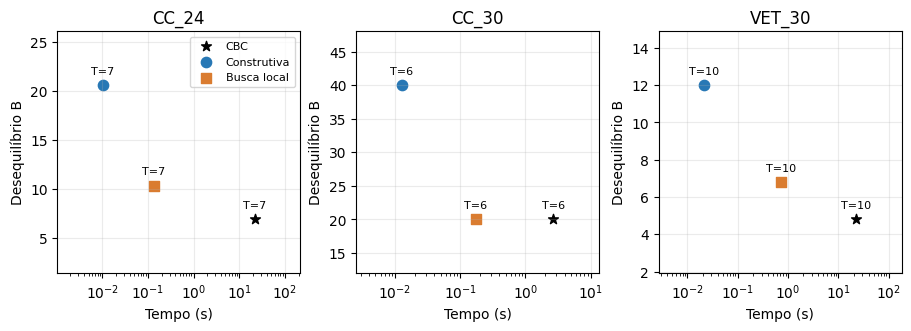

In [15]:
def grafico_comparacao(linhas,pasta):
    fig,eixos=plt.subplots(1,3,figsize=(9,3.2),constrained_layout=True)
    for ax,nome in zip(eixos,['CC_24','CC_30','VET_30']):
        for metodo,cor,marca in [('CBC','black','*'),('Construtiva','#2878b5','o'),('Busca local','#da7c30','s')]:
            linha=next(r for r in linhas if r['cenario']==nome and r['metodo']==metodo)
            if linha['T'] is not None:
                x=max(linha['tempo_s'],1e-6)
                ax.scatter(x,linha['B'],color=cor,marker=marca,label=metodo,s=55)
                ax.annotate(f"T={linha['T']}",(x,linha['B']),xytext=(0,8),textcoords='offset points',fontsize=8,ha='center')
        ax.set(xscale='log',xlabel='Tempo (s)',ylabel='Desequilíbrio B',title=nome)
        ax.grid(alpha=.25)
        ax.margins(x=.3,y=.4)
    eixos[0].legend(fontsize=8,loc='best')
    fig.savefig(pasta/'qualidade_tempo.png',dpi=180)
    display(fig)
    plt.close(fig)

grafico_comparacao(linhas,pasta_resultados)

## 9. Examinar um plano
Altere o cenário ou o método abaixo para conferir disciplinas e créditos de cada período.

In [16]:
CENARIO_EXEMPLO='CC_24'
METODO_EXEMPLO='busca_local'
dados=instancias[CENARIO_EXEMPLO]
plano=registro['resultados'][CENARIO_EXEMPLO]['heuristica'][METODO_EXEMPLO]
if plano:
    mostrar_tabela(['Período','Créditos','Disciplinas'],
        [[t,sum(dados['disciplinas'][i]['creditos'] for i in plano if plano[i]==t),
          ', '.join(sorted(i for i in plano if plano[i]==t))] for t in range(1,max(plano.values())+1)])

| Período | Créditos | Disciplinas |
| --- | --- | --- |
| 1 | 24 | GCC260, GCC261, GCC263, GMM102, GMM104, GMM135 |
| 2 | 24 | GAC107, GCC117, GCC122, GCC188, GCC219, GCC220 |
| 3 | 20 | GCC108, GCC116, GCC125, GCC253, GMM106 |
| 4 | 22 | GAC106, GAC115, GAC116, GAC120, GCC118, GCC241 |
| 5 | 24 | GCC123, GCC128, GCC129, GCC130, GCC175, GCC225 |
| 6 | 20 | GCH189, GEF111, GES101, GMM103, GMM111, TCC1070 |
| 7 | 22 | GAC104, GAC105, GCC222, GCH110, GDE123, GFI105, GMM101, GMM110, TCC1071 |

## 10. Leitura dos resultados e limites
O CBC pode provar ótimo ou retornar um plano ainda sem prova de ótimo. A busca local termina quando suas duas vizinhanças não oferecem melhora; isso não é uma garantia global.

Há uma execução por cenário: os tempos são observações desta máquina, sem análise estatística ou controle de carga. Não são modeladas oferta, horários, vagas e reprovações futuras. A análise sistemática de incertezas e a apresentação final são etapas posteriores.

In [17]:
otimos=sum(r['exato']['otimo'] for r in registro['resultados'].values())
viaveis=sum(bool(r['exato']['plano']) for r in registro['resultados'].values())
melhoras=sum(objetivo(instancias[n],r['heuristica']['busca_local'])[1] < objetivo(instancias[n],r['heuristica']['construtiva'])[1]-1e-8
             for n,r in registro['resultados'].items() if r['heuristica']['construtiva'])
print(f'CBC: {viaveis} cenários com plano, {otimos} com os dois objetivos provados ótimos.')
print(f'Busca local: melhora de B em {melhoras} cenários.')
print('Planos, tempos, status e limites estão em:',pasta_resultados.name)

CBC: 8 cenários com plano, 4 com os dois objetivos provados ótimos.
Busca local: melhora de B em 5 cenários.
Planos, tempos, status e limites estão em: resultados


## Fontes dos dados
- [Computação - matriz 313](https://sig.ufla.br/modulos/publico/matrizes_curriculares/index.php?cod_matriz_curricular=313&op=abrir).
- [Veterinária - matriz 302](https://sig.ufla.br/modulos/publico/matrizes_curriculares/index.php?cod_matriz_curricular=302&op=abrir).
- [TCC I - ementa 9785](https://sig.ufla.br/modulos/publico/matrizes_curriculares/gerar_ementa.php?cod_disciplina=9785) e [TCC II - ementa 9786](https://sig.ufla.br/modulos/publico/matrizes_curriculares/gerar_ementa.php?cod_disciplina=9786).
- Enunciado GCC118, semestre 2026/2, fornecido na disciplina.